In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [2]:
cust_data = pd.read_csv("shop_smart_ecommerce.csv")
cust_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [3]:
cust_data.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
pd.crosstab(cust_data["Browser"],cust_data["Revenue"],normalize='index')*100

Revenue,False,True
Browser,,
1,85.174655,14.825345
2,84.637608,15.362392
3,95.238095,4.761905
4,82.336957,17.663043
5,81.584582,18.415418
6,88.505747,11.494253
7,87.755102,12.244898
8,84.444444,15.555556
9,100.000000,0.000000


In [5]:
le = LabelEncoder()
cust_data["Month"] = le.fit_transform(cust_data["Month"])
cust_data["VisitorType"] = le.fit_transform(cust_data["VisitorType"])
cust_data["Weekend"] = le.fit_transform(cust_data["Weekend"])
cust_data["Month"].unique()

array([2, 5, 6, 8, 4, 3, 0, 7, 9, 1])

In [6]:
X = cust_data.drop("Revenue",axis=1)
y = cust_data["Revenue"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,stratify=y)

In [10]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
accuracy_score(y_test,y_pred)

0.8564476885644768

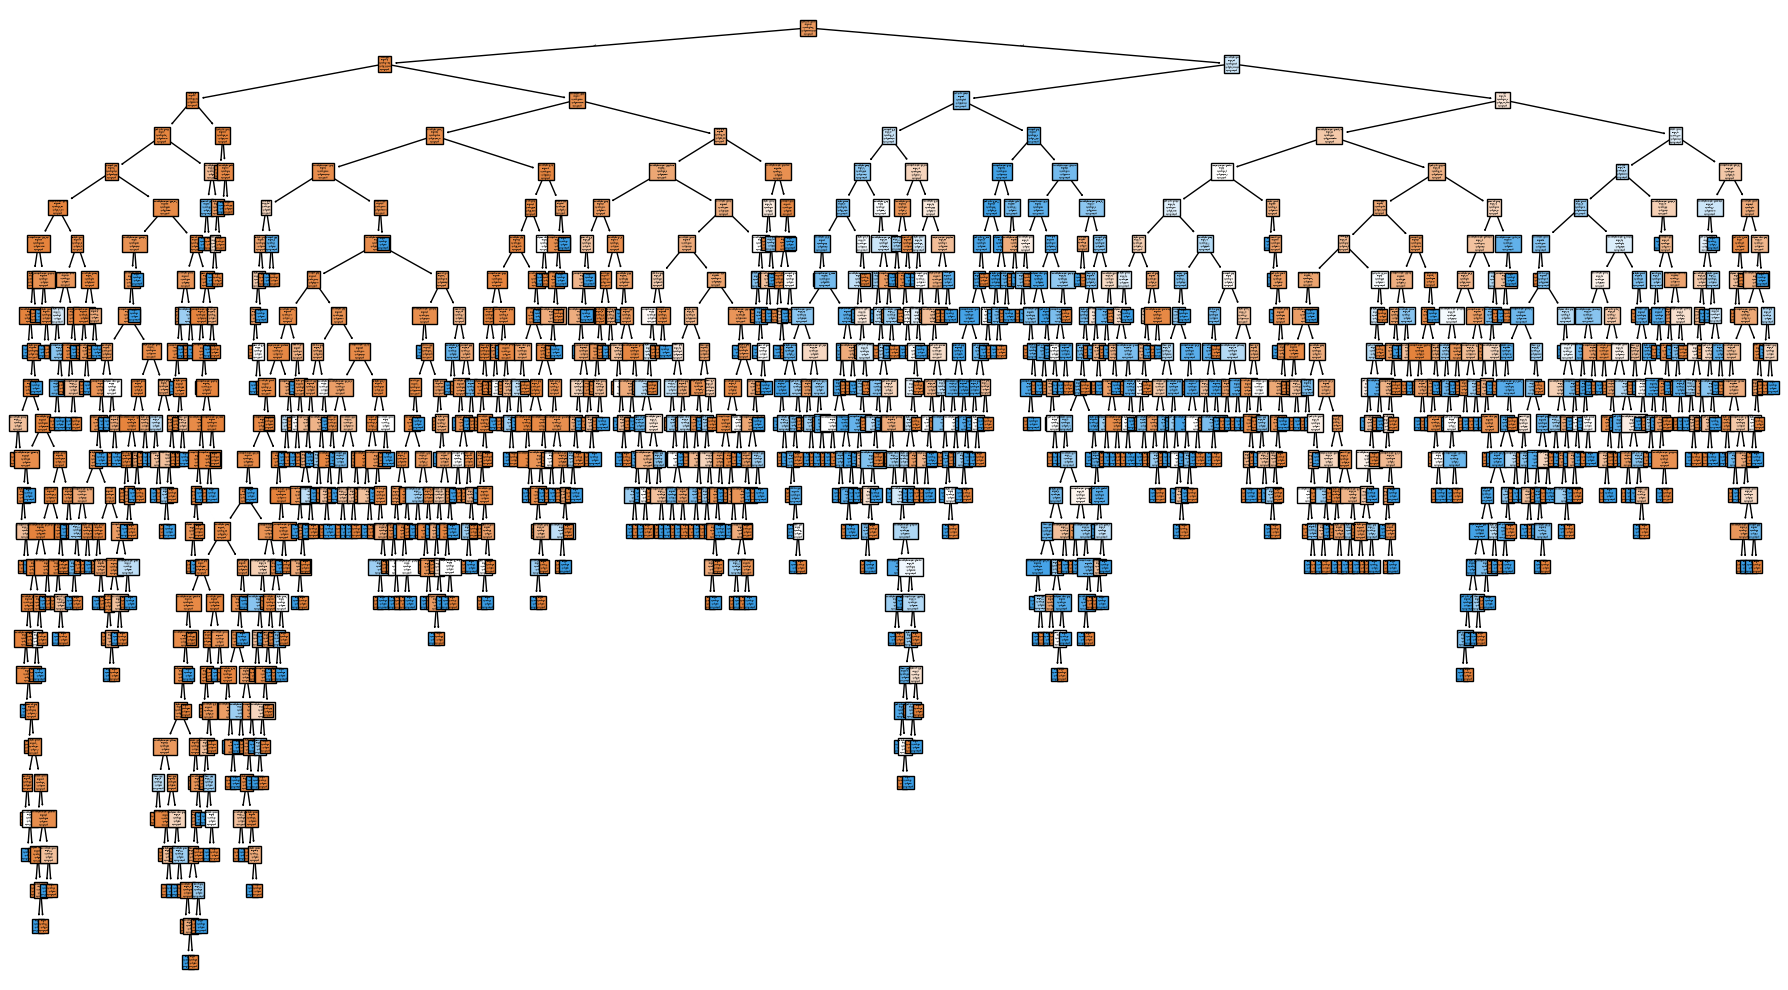

In [11]:
plt.figure(figsize=(18,10))
plot_tree(
    dtc,
    feature_names= X.columns,
    class_names=["made","not made"],
    filled= True
    
)
plt.tight_layout()
plt.show()

In [1]:
dtc = DecisionTreeClassifier(max_depth=5,min_samples_split=110)
dtc.fit(X_train,y_train)
y_pred = dtc.predict(X_test)
accuracy_score(y_test,y_pred)

NameError: name 'DecisionTreeClassifier' is not defined

In [ ]:
plt.figure(figsize=(18,10))
plot_tree(
    dtc,
    feature_names= X.columns,
    class_names=["made","not made"],
    filled= True
    
)
plt.tight_layout()
plt.show()